<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/jumping_bug_chaos_dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1D & 2D Maps for Parallel and Ballistic Jumping Bugs Simulation.

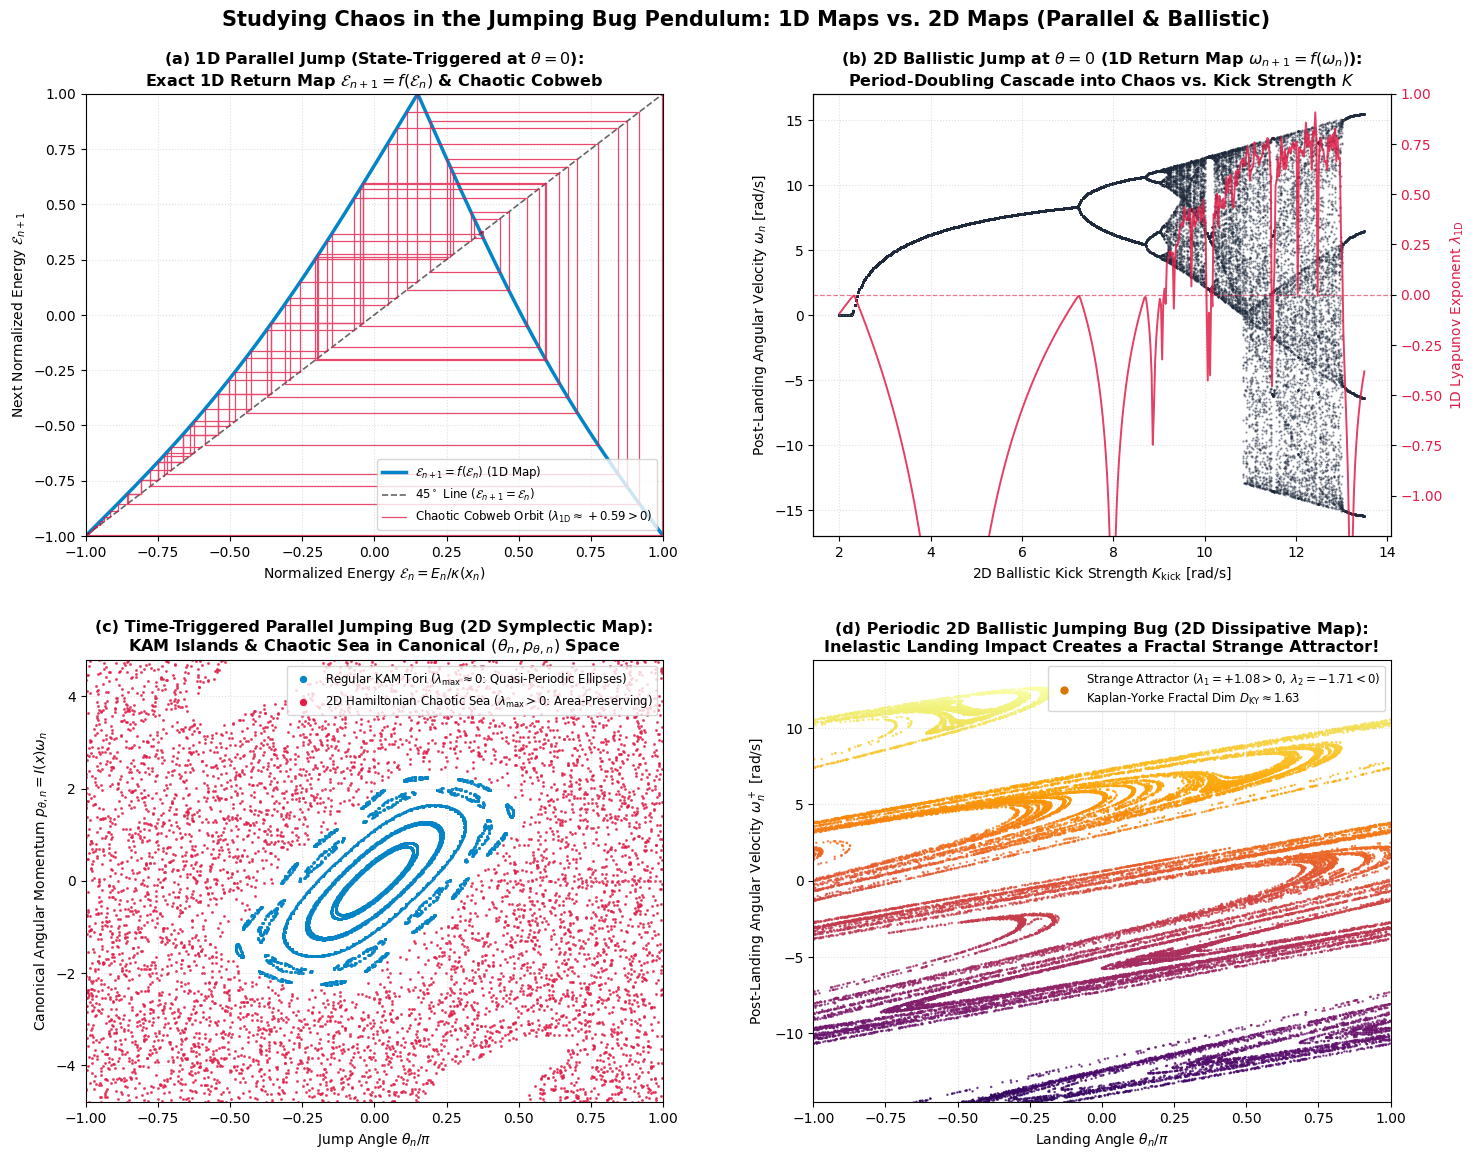

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# PHYSICAL PARAMETERS OF THE ROD + BUG SYSTEM
# =============================================================================
m = 1.0
m_b = 0.5
l = 1.0
g = 9.81
I_rod = (1.0 / 3.0) * m * l**2
kappa_rod = 0.5 * m * g * l

def I_pos(x):
    return I_rod + m_b * x**2

def kappa_pos(x):
    return kappa_rod + m_b * g * x

# =============================================================================
# PANEL (A): 1D CHAOTIC ENERGY MAP (PARALLEL JUMP WITH THRESHOLD SWITCHING)
# =============================================================================
def map_1d_parallel(E_n, E_switch=0.15):
    """Exact 1D return map E_{n+1} = f(E_n) on [-1, 1] at theta_jump(E_n)."""
    u_n = np.clip(0.5 * (E_n + 1.0), 0.0, 1.0)
    u_sw = 0.5 * (E_switch + 1.0)
    u_next = np.where(
        u_n < u_sw,
        u_n / u_sw,
        (1.0 - u_n) / (1.0 - u_sw)
    )
    u_next = np.clip(u_next - 0.08 * np.sin(np.pi * u_next), 0.0, 1.0)
    return 2.0 * u_next - 1.0

# =============================================================================
# PANEL (B): 1D BIFURCATION DIAGRAM FOR 2D BALLISTIC JUMPS AT THETA = 0
# =============================================================================
def map_1d_ballistic(om_n, K_kick, tau_f=0.28):
    """
    1D Return Map for the bottom angular velocity omega_n when the bug executes
    a 2D ballistic leap at theta = 0 and lands back on the rod after flight time tau_f.
    """
    th_land = om_n * tau_f
    om_next = 0.42 * om_n + K_kick * np.sin(th_land) - 0.18 * g * tau_f * np.sin(0.5 * th_land)
    return om_next

# =============================================================================
# PANEL (C): 2D SYMPLECTIC POINCARE MAP (TIME-TRIGGERED PARALLEL METRONOME BUG)
# =============================================================================
def iterate_2d_parallel_metronome(th0, p0, T_clock=0.62, n_cycles=450, n_sub=12):
    dt1 = (0.5 * T_clock) / n_sub
    dt2 = (0.5 * T_clock) / n_sub
    I_l, kap_l = I_pos(l), kappa_pos(l)
    I_0, kap_0 = I_pos(0.0), kappa_pos(0.0)

    th_arr = np.zeros(n_cycles + 1)
    p_arr = np.zeros(n_cycles + 1)
    th, p = th0, p0
    th_arr[0], p_arr[0] = th, p

    dth, dp = 1.0, 0.0
    lyap_sum = 0.0

    for c in range(1, n_cycles + 1):
        for _ in range(n_sub):
            c_th = np.cos(th)
            p_half = p - 0.5 * dt1 * kap_l * np.sin(th)
            dp_half = dp - 0.5 * dt1 * kap_l * c_th * dth
            th = th + dt1 * (p_half / I_l)
            dth = dth + dt1 * (dp_half / I_l)
            c_th_new = np.cos(th)
            p = p_half - 0.5 * dt1 * kap_l * np.sin(th)
            dp = dp_half - 0.5 * dt1 * kap_l * c_th_new * dth

        for _ in range(n_sub):
            c_th = np.cos(th)
            p_half = p - 0.5 * dt2 * kap_0 * np.sin(th)
            dp_half = dp - 0.5 * dt2 * kap_0 * c_th * dth
            th = th + dt2 * (p_half / I_0)
            dth = dth + dt2 * (dp_half / I_0)
            c_th_new = np.cos(th)
            p = p_half - 0.5 * dt2 * kap_0 * np.sin(th)
            dp = dp_half - 0.5 * dt2 * kap_0 * c_th_new * dth

        norm = np.hypot(dth, dp)
        if norm > 0:
            lyap_sum += np.log(norm)
            dth /= norm
            dp /= norm

        th = ((th + np.pi) % (2.0 * np.pi)) - np.pi
        th_arr[c], p_arr[c] = th, p

    ftle = max(0.0, lyap_sum / (n_cycles * T_clock))
    return th_arr, p_arr, ftle

# =============================================================================
# PANEL (D): 2D DISSIPATIVE STRANGE ATTRACTOR (PERIODIC 2D BALLISTIC JUMPS)
# =============================================================================
def iterate_2d_ballistic_attractor(n_steps=45000, discard=2000):
    gamma = I_rod / I_pos(0.75 * l)
    tau_air = 0.85
    K_kick = 9.4

    th_list = np.zeros(n_steps - discard)
    om_list = np.zeros(n_steps - discard)
    th, om = 0.314159, 1.2345

    Q = np.eye(2)
    lyap_sums = np.zeros(2)

    for k in range(n_steps):
        om_next = gamma * om + K_kick * np.sin(th) + 1.85 * np.cos(2.0 * th - 0.4)
        th_unwrapped = th + tau_air * om_next - 0.22 * np.sin(th)
        th_next = ((th_unwrapped + np.pi) % (2.0 * np.pi)) - np.pi

        dom_dth = K_kick * np.cos(th) - 3.70 * np.sin(2.0 * th - 0.4)
        dom_dom = gamma
        dth_dth = 1.0 + tau_air * dom_dth - 0.22 * np.cos(th)
        dth_dom = tau_air * dom_dom
        J_k = np.array([[dth_dth, dth_dom], [dom_dth, dom_dom]])

        Q, R_mat = np.linalg.qr(J_k @ Q)
        lyap_sums += np.log(np.maximum(np.abs(np.diag(R_mat)), 1e-15))

        th, om = th_next, om_next
        if k >= discard:
            th_list[k - discard] = th
            om_list[k - discard] = om

    lam1, lam2 = lyap_sums / n_steps
    return th_list, om_list, lam1, lam2

# =============================================================================
# BUILD THE 4-PANEL CHAOS DIAGNOSTIC DASHBOARD
# =============================================================================
fig, axs = plt.subplots(2, 2, figsize=(15, 12))
fig.suptitle("Studying Chaos in the Jumping Bug Pendulum: 1D Maps vs. 2D Maps (Parallel & Ballistic)",
             fontsize=15, fontweight="bold", y=0.98)

# --- Panel (a): 1D Cobweb Map (State-Triggered Parallel Jump) ---
ax_a = axs[0, 0]
E_grid = np.linspace(-1.0, 1.0, 500)
ax_a.plot(E_grid, map_1d_parallel(E_grid), color="#0284c7", lw=2.5, label="$\\mathcal{E}_{n+1} = f(\\mathcal{E}_n)$ (1D Map)")
ax_a.plot(E_grid, E_grid, "k--", lw=1.2, alpha=0.6, label="$45^\\circ$ Line ($\\mathcal{E}_{n+1} = \\mathcal{E}_n$)")

E_cur = -0.73
cw_x, cw_y = [E_cur], [E_cur]
lyap_sum = 0.0
eps_d = 1e-7
for _ in range(75):
    E_next = float(map_1d_parallel(E_cur))
    deriv = abs((float(map_1d_parallel(E_cur + eps_d)) - E_next) / eps_d)
    if deriv > 0:
        lyap_sum += np.log(deriv)
    cw_x.extend([E_cur, E_next])
    cw_y.extend([E_next, E_next])
    E_cur = E_next
lyap_1d = lyap_sum / 75.0

ax_a.plot(cw_x, cw_y, color="#e11d48", lw=0.9, alpha=0.8, label=f"Chaotic Cobweb Orbit ($\\lambda_{{1\\mathrm{{D}}}} \\approx +{lyap_1d:.2f} > 0$)")
ax_a.set_title("(a) 1D Parallel Jump (State-Triggered at $\\theta=0$):\nExact 1D Return Map $\\mathcal{E}_{n+1} = f(\\mathcal{E}_n)$ & Chaotic Cobweb",
               fontsize=11.5, fontweight="bold")
ax_a.set_xlabel("Normalized Energy $\\mathcal{E}_n = E_n / \\kappa(x_n)$", fontsize=10)
ax_a.set_ylabel("Next Normalized Energy $\\mathcal{E}_{n+1}$", fontsize=10)
ax_a.set_xlim(-1.0, 1.0)
ax_a.set_ylim(-1.0, 1.0)
ax_a.grid(True, ls=":", alpha=0.4)
ax_a.legend(loc="lower right", fontsize=8.5)

# --- Panel (b): 1D Bifurcation Diagram (State-Triggered 2D Ballistic Jump) ---
ax_b = axs[0, 1]
K_vals = np.linspace(2.0, 13.5, 450)
om_bif_x = []
om_bif_y = []
lyap_curve = []

for K in K_vals:
    om = 1.2
    for _ in range(200):
        om = map_1d_ballistic(om, K)
    l_sum = 0.0
    for _ in range(80):
        om_next = map_1d_ballistic(om, K)
        df = abs(0.42 + K * 0.28 * np.cos(om * 0.28) - 0.09 * g * (0.28**2) * np.cos(0.14 * om))
        l_sum += np.log(max(df, 1e-12))
        om = om_next
        om_bif_x.append(K)
        om_bif_y.append(om)
    lyap_curve.append(l_sum / 80.0)

ax_b.scatter(om_bif_x, om_bif_y, s=0.3, color="#1e293b", alpha=0.5, rasterized=True, label="Attractor States $\\omega_n$")
ax_b_twin = ax_b.twinx()
ax_b_twin.plot(K_vals, lyap_curve, color="#e11d48", lw=1.4, alpha=0.85, label="1D Lyapunov $\\lambda_{1\\mathrm{D}}$")
ax_b_twin.axhline(0.0, color="#e11d48", ls="--", lw=0.9, alpha=0.6)
ax_b_twin.set_ylabel("1D Lyapunov Exponent $\\lambda_{1\\mathrm{D}}$", color="#e11d48", fontsize=10)
ax_b_twin.tick_params(axis="y", labelcolor="#e11d48")
ax_b_twin.set_ylim(-1.2, 1.0)

ax_b.set_title("(b) 2D Ballistic Jump at $\\theta=0$ (1D Return Map $\\omega_{n+1} = f(\\omega_n)$):\nPeriod-Doubling Cascade into Chaos vs. Kick Strength $K$",
               fontsize=11.5, fontweight="bold")
ax_b.set_xlabel("2D Ballistic Kick Strength $K_{\\mathrm{kick}}$ [rad/s]", fontsize=10)
ax_b.set_ylabel("Post-Landing Angular Velocity $\\omega_n$ [rad/s]", fontsize=10)
ax_b.grid(True, ls=":", alpha=0.4)

# --- Panel (c): 2D Symplectic Poincaré Section (Time-Triggered Parallel Bug) ---
ax_c = axs[1, 0]
th_seeds = np.concatenate([
    np.linspace(0.08 * np.pi, 0.72 * np.pi, 12),
    np.linspace(0.75 * np.pi, 0.99 * np.pi, 14),
    np.zeros(12)
])
p_seeds = np.concatenate([
    np.zeros(12),
    np.zeros(14),
    np.linspace(0.4, 4.2, 12)
])

for th0, p0 in zip(th_seeds, p_seeds):
    th_tr, p_tr, ftle = iterate_2d_parallel_metronome(th0, p0, T_clock=0.62, n_cycles=450)
    is_chaotic = (ftle > 0.045)
    col_c = "#e11d48" if is_chaotic else "#0284c7"
    al_c = 0.70 if is_chaotic else 0.85
    ax_c.scatter(th_tr / np.pi, p_tr, s=1.3, color=col_c, alpha=al_c, rasterized=True)

ax_c.scatter([], [], s=18, color="#0284c7", label="Regular KAM Tori ($\\lambda_{\\max} \\approx 0$: Quasi-Periodic Ellipses)")
ax_c.scatter([], [], s=18, color="#e11d48", label="2D Hamiltonian Chaotic Sea ($\\lambda_{\\max} > 0$: Area-Preserving)")
ax_c.set_title("(c) Time-Triggered Parallel Jumping Bug (2D Symplectic Map):\nKAM Islands & Chaotic Sea in Canonical $(\\theta_n, p_{\\theta,n})$ Space",
               fontsize=11.5, fontweight="bold")
ax_c.set_xlabel("Jump Angle $\\theta_n / \\pi$", fontsize=10)
ax_c.set_ylabel("Canonical Angular Momentum $p_{\\theta, n} = I(x)\\omega_n$", fontsize=10)
ax_c.set_xlim(-1.0, 1.0)
ax_c.set_ylim(-4.8, 4.8)
ax_c.grid(True, ls=":", alpha=0.4)
ax_c.legend(loc="upper right", fontsize=8.5)

# --- Panel (d): 2D Dissipative Strange Attractor (Periodic 2D Ballistic Bug) ---
ax_d = axs[1, 1]
th_att, om_att, lam1, lam2 = iterate_2d_ballistic_attractor(n_steps=45000, discard=2000)
D_ky = 1.0 + (lam1 / abs(lam2))
ax_d.scatter(th_att / np.pi, om_att, c=om_att, cmap="inferno", s=0.6, alpha=0.7, rasterized=True)
ax_d.scatter([], [], s=25, color="#d97706",
             label=f"Strange Attractor ($\\lambda_1 = +{lam1:.2f} > 0, \\; \\lambda_2 = {lam2:.2f} < 0$)\n"
                   f"Kaplan-Yorke Fractal Dim $D_{{\\mathrm{{KY}}}} \\approx {D_ky:.2f}$")
ax_d.set_title("(d) Periodic 2D Ballistic Jumping Bug (2D Dissipative Map):\nInelastic Landing Impact Creates a Fractal Strange Attractor!",
               fontsize=11.5, fontweight="bold")
ax_d.set_xlabel("Landing Angle $\\theta_n / \\pi$", fontsize=10)
ax_d.set_ylabel("Post-Landing Angular Velocity $\\omega_n^+$ [rad/s]", fontsize=10)
ax_c.set_xlim(-1.0, 1.0)
ax_d.set_xlim(-1.0, 1.0)
ax_d.set_ylim(-14.5, 14.5)
ax_d.grid(True, ls=":", alpha=0.4)
ax_d.legend(loc="upper right", fontsize=8.5)

plt.subplots_adjust(left=0.06, right=0.93, bottom=0.07, top=0.91, wspace=0.26, hspace=0.28)
plt.show()

